# Capítulo 5 · Proyecto 1: comparación de modelos

> ¿Qué modelo recomendarías para clasificar la presencia de enfermedad cardiaca y qué resultados respaldan tu elección?

Utiliza el dataset [UCI Heart Disease de Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data), archivo `heart_disease_uci.csv`, y documenta tu trabajo en un notebook reproducible.

## Etapa 1: limpieza y preparación

1. Identifica los valores faltantes y los valores inválidos, decide cómo tratarlos y justifica brevemente tu decisión.
2. Explora los posibles outliers y explica si los conservarás o aplicarás algún tratamiento.
3. Prepara las variables numéricas y categóricas. Crea el objetivo binario (**target**) a partir de `num`: **target = 0 si num = 0** (ausencia de enfermedad) y **target = 1 si num es 1, 2, 3 o 4** (presencia de enfermedad). Excluye tanto `num` como el target de las entradas del modelo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "heart_disease_uci.csv")
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


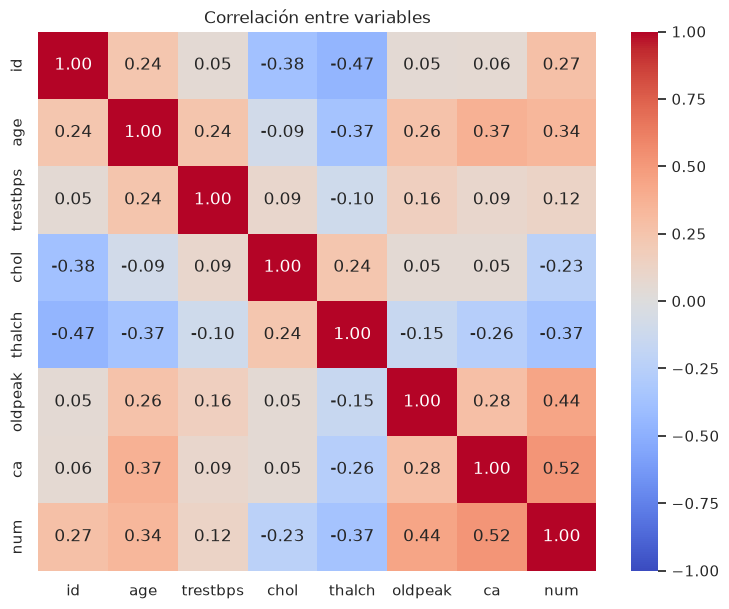

In [2]:
correlaciones = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

numericas: age, id, trestbps, chol, thaclh, oldpeak

categoricas: dataset, cp, restecg, slope, thal,

ordinal: ca

binarias: sex, fbs, exang  

In [3]:
# Tu código aquí
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum())

Filas y columnas: (920, 16)
Valores nulos: id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


|Faltantes:|Metodo| 
|------|--------|
|trestbps|mediana|
|chol|mediana|
|fbs|moda|
|restecg|moda|
|thalch|mediana|
|exang|moda con cp|
|oldpeak|mediana|
|__slope__|moda con cp|
|__ca__|moda con cp|
|__thal__|moda con cp|

In [4]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


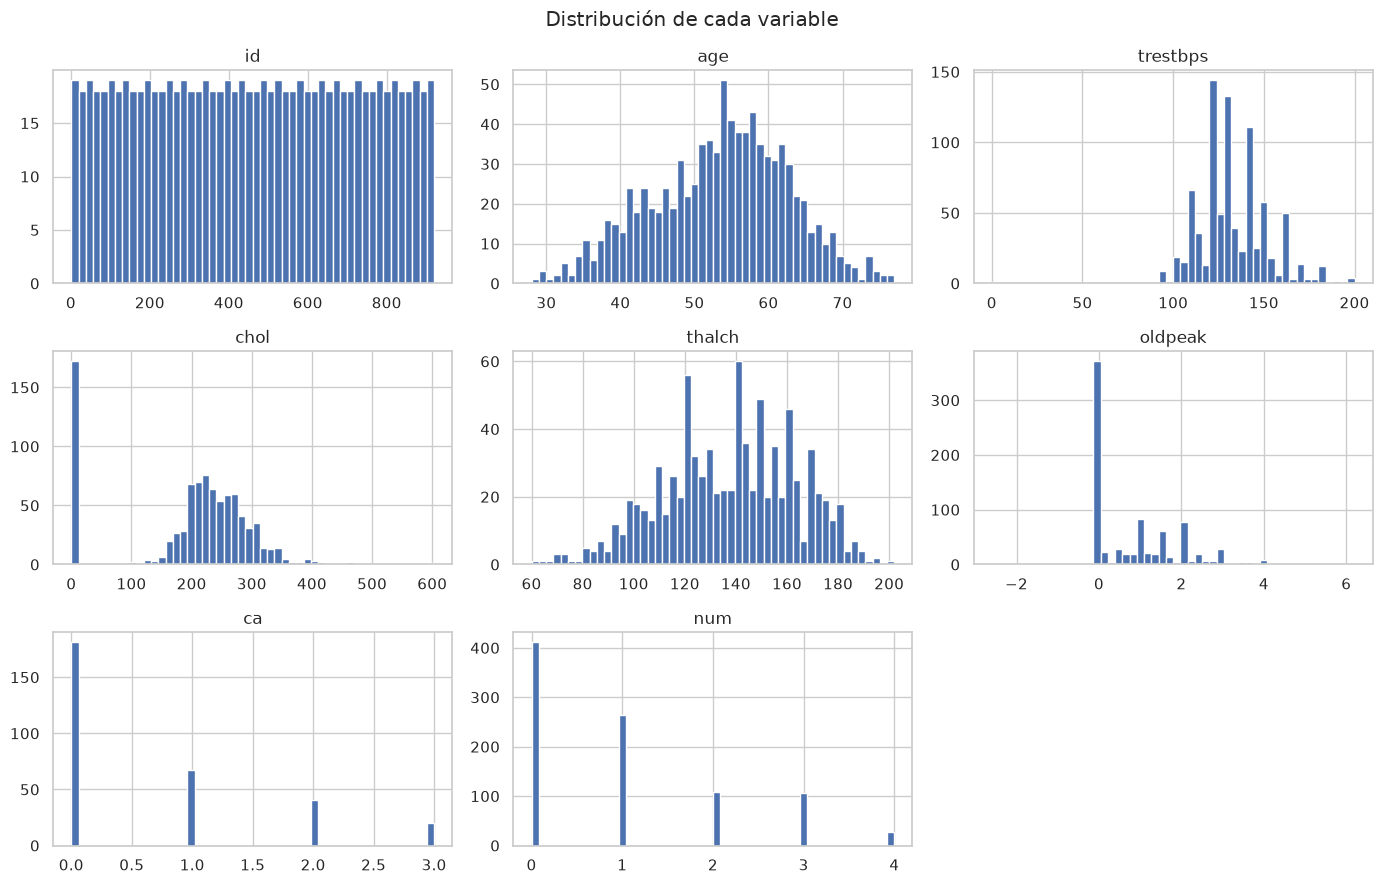

In [5]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

## Mediana


In [6]:
mediana = df["trestbps"].median()
print("Desviación estándar antes:  ", round(df["trestbps"].std(), 2))

df["trestbps"] = df["trestbps"].fillna(mediana)
print("Desviación estándar después:", round(df["trestbps"].std(), 2))

Desviación estándar antes:   19.07
Desviación estándar después: 18.45


In [7]:
mediana = df["chol"].median()
print("Desviación estándar antes:  ", round(df["chol"].std(), 2))

df["chol"] = df["chol"].fillna(mediana)
print("Desviación estándar después:", round(df["chol"].std(), 2))

Desviación estándar antes:   110.78
Desviación estándar después: 109.04


In [8]:
mediana = df["thalch"].median()
print("Desviación estándar antes:  ", round(df["thalch"].std(), 2))

df["thalch"] = df["thalch"].fillna(mediana)
#df["thalch"] = df["thalch"].fillna(df.groupby("cp")["thalch"].transform("median"))
print("Desviación estándar después:", round(df["thalch"].std(), 2))

Desviación estándar antes:   25.93
Desviación estándar después: 25.15


In [9]:
mediana = df["oldpeak"].median()
print("Desviación estándar antes:  ", round(df["oldpeak"].std(), 2))

df["oldpeak"] = df["oldpeak"].fillna(mediana)
print("Desviación estándar después:", round(df["oldpeak"].std(), 2))

Desviación estándar antes:   1.09
Desviación estándar después: 1.06


## Moda


In [10]:
moda = df["restecg"].mode()[0]       # mode() devuelve una Series: nos quedamos con el primer valor
print("Moda:", moda)

df["restecg"] = df["restecg"].fillna(moda)
df["restecg"].value_counts()

Moda: normal


restecg
normal              553
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64

In [11]:
moda = df["fbs"].mode()[0]       # mode() devuelve una Series: nos quedamos con el primer valor
print("Moda:", moda)

df["fbs"] = df["fbs"].fillna(moda)
df["fbs"].value_counts()

Moda: False


fbs
False    782
True     138
Name: count, dtype: int64

## Imputacion por grupo

In [12]:
moda_cp = df.groupby("cp")["exang"].agg(lambda s: s.mode().iloc[0])   # una moda por categoría de cp
df["exang"] = df["exang"].fillna(df["cp"].map(moda_cp))

In [13]:
moda_cp = df.groupby("cp")["ca"].agg(lambda s: s.mode().iloc[0])   # una moda por categoría de cp
df["ca"] = df["ca"].fillna(df["ca"].map(moda_cp))

In [14]:
moda_cp = df.groupby("cp")["thal"].agg(lambda s: s.mode().iloc[0])   # una moda por categoría de cp
df["thal"] = df["thal"].fillna(df["cp"].map(moda_cp))

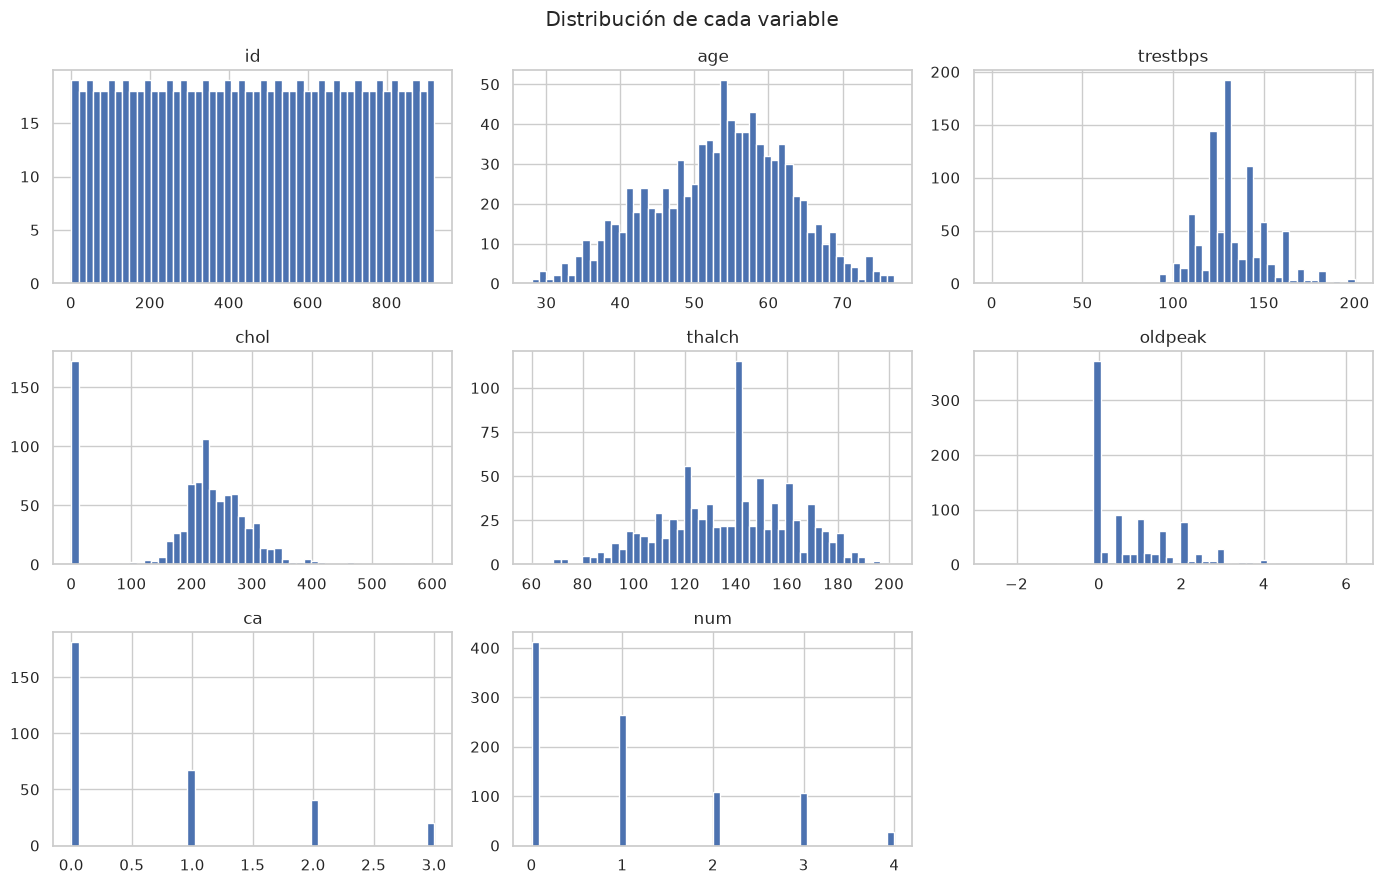

In [15]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

In [16]:
df["target"]=np.where(df["num"] == 0, 0, 1)

In [17]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


## Etapa 2: entrenamiento y comparación

1. Separa los datos en entrenamiento, validación y prueba, usando las mismas particiones para todos los modelos y `random_state=42`. Ajusta la imputación y el escalado únicamente con entrenamiento.
2. Entrena **regresión logística, KNN y árbol de decisión**, aplicando escalado cuando corresponda.
3. Usa **GridSearchCV** con validación cruzada sobre los datos de entrenamiento para buscar los mejores hiperparámetros de los tres modelos. Compara las mejores configuraciones en validación y selecciona el modelo con mejor resultado según una métrica justificada.
4. Compara entrenamiento y evaluación para identificar sobreajuste. Presenta una tabla de métricas y las matrices de confusión de prueba.
5. Recomienda un modelo y justifica tu elección con los resultados: qué errores comete, qué ventajas tiene y cuáles son sus limitaciones.